# 05 — Single-run policy study

**Specification:** Introduction and Methods, public data only. This notebook implements prediction/support diagnostics, finite-grid optimization, baselines, an observable-information oracle, 30 independently generated/refitted datasets per main scenario, paired uncertainty, sensitivities, and 500 date-block bootstrap refits. All outputs stay under `data/study/`; source assets are unchanged.

Main scenarios cross binding/bargaining institutions with historical/randomized floors. Each simulation has 50,000 vehicles and a date-preserving 60/20/20 split. Policy evaluation uses a seeded random 200-vehicle portfolio from each test period, not the entire test fleet; conclusions concern portfolios of this size. Fixed model specifications come from prior development comparisons and are refitted in every replication. Tuning is not repeated on test outcomes.

**Primary calibration protocol:** chronological validation only. The target-period calibration of notebook 04 is not silently imported into this prospective experiment. Its results answer a separate representative-cohort question. This study may find that forecast error makes the optimization constraint unreliable.

Repeated auctions remain the explicitly deferred extension. This completes the single-run experiment, not that extension. Runs are checkpointed by scenario/seed for inspection and restart.


In [1]:
from pathlib import Path
import json, hashlib, time, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit, ndtr
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import eye, kron, csr_matrix, vstack
from scipy.stats import norm, t as student_t
from numpy.polynomial.hermite import hermgauss
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import log_loss, brier_score_loss, mean_squared_error
from IPython.display import display
import joblib, cloudpickle
OUT=Path('data/study');OUT.mkdir(parents=True,exist_ok=True)
CAL=Path('data/calibration');metadata=json.loads((CAL/'calibration_metadata.json').read_text())
CONFIG=metadata['config'].copy();fits=joblib.load(CAL/'fitted_calibration.joblib')
FILES=metadata['source_files'];targets=pd.read_csv(CAL/'calibration_targets.csv').set_index('group')
coverage=pd.read_csv('data/source_audit/audit_summary.csv').set_index('seller_group')
N=50000;PORTFOLIO=200;REPLICATIONS=30;BOOTSTRAPS=500
TARGETS=[.40,.50,.60,.70,.80];SEED=6940;MIN_CATEGORY_COUNT=100
ORACLE_NODES=41;ORACLE_CHECK_NODES=81
started=time.perf_counter()


In [2]:
NUMERIC=['age','log_mileage','log_benchmark','month_sin','month_cos']
CATEGORICAL=['make','condition','location','seller_group']
FEATURES=NUMERIC+['floor_ratio']+CATEGORICAL
FORBIDDEN={'sold','price','high_bid','bargaining_accepted_below_floor','vehicle_id','run_id',
           'private_signal','market_shock','sale_uniform','true_sale_probability_given_latents'}
assert not set(FEATURES)&FORBIDDEN
origin=pd.Timestamp('2006-11-01')  # unused here: calendar_days is not in FEATURES; kept so features() matches notebooks 03-04

from auction_helpers import (RestrictedCubicSpline, make_features, make_preprocessing,
                              fit_correction, correct)

def features(d):
    return make_features(d,origin,CATEGORICAL,FEATURES)

def preprocessing(knots=None):
    return make_preprocessing(knots,NUMERIC,CATEGORICAL,MIN_CATEGORY_COUNT)



## Fixed generator and primary refitting protocol

Keep the calibrated generator fixed between replications; sensitivities alter named assumptions. Fresh seeds generate new covariates, private information, common daily shocks, and outcomes. Historical and randomized floor assignments remain separate. The predictor never reads the latent output.

Logistic regression uses the development-selected three-knot restricted cubic spline with seasonal features and no extrapolated linear calendar trend. Conditional prices use the selected 15-leaf booster, trained on sales, with training-residual retransformation. Group/floor-band smearing replaces pooled smearing when supported cells depart by more than 10%. A training-derived grouping defines candidate support. Chronological validation selects raw versus group-sigmoid probabilities using disjoint earlier/later validation dates, then refits only the selected correction on validation data.


In [3]:
def model_frame(d):
    x=d.copy();x['log_mileage']=np.log1p(x.mileage);x['log_benchmark']=np.log(x.benchmark)
    if 'month' not in x:x['month']=pd.to_datetime(x.auction_date).dt.to_period('M').astype(str)
    return x

def generate(seed, institution="binding", assignment="historical", n=50000):
    rng=np.random.default_rng(seed)
    total=n
    group_sizes=rng.multinomial(total,np.array([targets.loc[g,'base_n'] for g in FILES])/targets.base_n.sum())
    frames=[]; latent_frames=[]; generation_diagnostics=[]
    for (group,f), n in zip(fits.items(),group_sizes):
        joint=f['joint']; idx=rng.choice(len(joint),n,p=joint['count']/joint['count'].sum())
        x=joint.iloc[idx].drop(columns='count').reset_index(drop=True).copy()
        x['seller_group']=group
        x['mileage']=0.0; x['benchmark']=1.0
        for field,transform in [('mileage',np.expm1),('benchmark',np.exp)]:
            m,residual=f[field]
            raw=transform(m.predict(model_frame(x))+rng.choice(residual,n))
            low,high=f[field+'_bounds']
            x[field]=np.clip(raw,max(0,low),high)
            generation_diagnostics.append(dict(group=group,field=field,clipped=int(((raw<max(0,low))|(raw>high)).sum()),n=int(n)))
        private=rng.normal(size=n)
        m,residual=f['floor']
        floor_raw=np.exp(m.predict(model_frame(x))+rng.choice(residual,n)+CONFIG['private_floor_strength']*private)
        x['floor_ratio']=np.clip(floor_raw,*f['floor_ratio_bounds'])
        generation_diagnostics.append(dict(group=group,field='floor_ratio',clipped=int((x.floor_ratio.to_numpy()!=floor_raw).sum()),n=int(n)))
        start=pd.to_datetime(x.month+'-01')
        days=start.dt.days_in_month.to_numpy()
        dates=start+pd.to_timedelta((rng.random(n)*days).astype(int),unit='D')
        x['auction_date']=dates.clip(lower=pd.Timestamp(coverage.loc[group,'start']),upper=pd.Timestamp(coverage.loc[group,'end']))
        x['known_sale_fee']=f['fee'];x['holding_cost']=CONFIG['holding_cost'];x['retained_value']=CONFIG['retained_ratio']*x.benchmark
        frames.append(x)
        latent_frames.append(pd.DataFrame({'private_signal':private}))
    vehicles=pd.concat(frames,ignore_index=True)
    latents=pd.concat(latent_frames,ignore_index=True)
    vehicles['vehicle_id']=[f'SYN-{i:06}' for i in range(len(vehicles))]
    vehicles['run_id']=vehicles.vehicle_id+'-1';vehicles['run_number']=1
    latents['vehicle_id']=vehicles.vehicle_id
    unique_dates=np.sort(vehicles.auction_date.unique())
    shocks=dict(zip(unique_dates,rng.normal(0,CONFIG['market_sd'],len(unique_dates))))
    latents['market_shock']=vehicles.auction_date.map(shocks).to_numpy()
    latents['sale_uniform']=rng.random(len(vehicles))
    latents['price_residual_quantile']=rng.random(len(vehicles))
    latents['bid_uniform']=rng.random(len(vehicles))
    
    assert len(vehicles)==total
    assert vehicles.vehicle_id.is_unique
    
    
    intercepts=metadata['conversion_intercept_adjustments']; price_calibration=metadata['price_calibration']; scenario_frames={}; evaluation_frames=[]
    for assignment in [assignment]:
        x=vehicles.copy()
        if assignment=='randomized':
            for group in FILES:
                ix=x.index[x.seller_group.eq(group)]
                x.loc[ix,'floor_ratio']=rng.permutation(x.loc[ix,'floor_ratio'].to_numpy())
        q=np.empty(len(x));means={};prices={}
        for group,f in fits.items():
            ix=x.index[x.seller_group.eq(group)]; z=model_frame(x.loc[ix])
            conv=f['conversion']; prep=conv.steps[0][1]; fit=conv.steps[-1][1]
            scale=prep.named_transformers_['num'].scale_[-1]
            floor_coefficient=fit.coef_[0,len(['age','log_mileage','log_benchmark'])]/scale
            base=conv.decision_function(z)-floor_coefficient*z.floor_ratio.to_numpy()+CONFIG['floor_effect']*z.floor_ratio.to_numpy()
            base+=CONFIG.get('demand_shift',0.0)
            base+=CONFIG['private_sale_strength']*latents.loc[ix,'private_signal'].to_numpy()+latents.loc[ix,'market_shock'].to_numpy()
            q[ix]=expit(base+intercepts[group])
        for institution in [institution]:
            price=np.empty(len(x));mean=np.empty(len(x))
            for group,f in fits.items():
                ix=x.index[x.seller_group.eq(group)];z=model_frame(x.loc[ix])
                m,residual=f['binding' if institution=='binding' else 'price']
                location=m.predict(z)+CONFIG['private_price_strength']*latents.loc[ix,'private_signal'].to_numpy()
                epsilon=np.quantile(residual,latents.loc[ix,'price_residual_quantile'].to_numpy())
                # Same interpolated empirical residual distribution for draws and analytic means.
                ordered=np.sort(residual); delta=np.diff(ordered)
                interval_mean=np.exp(ordered[:-1])*np.divide(np.expm1(delta),delta,out=np.ones_like(delta),where=delta!=0)
                smear=float(interval_mean.mean())
                offset=z.floor_ratio.to_numpy() if institution=='binding' else 0.0
                key=group+'_'+institution
                location=location+np.log(price_calibration[key]['multiplier'])
                price[ix]=z.benchmark.to_numpy()*(offset+np.exp(location+epsilon))
                mean[ix]=z.benchmark.to_numpy()*(offset+np.exp(location)*smear)
            sold=latents.sale_uniform.to_numpy()<q
            result=x.copy();result['floor']=result.floor_ratio*result.benchmark
            result['sold']=sold.astype(int);result['price']=np.where(sold,price,np.nan)
            result['bargaining_accepted_below_floor']=sold & (price<result.floor)
            result['high_bid']=np.where(sold,np.minimum(price,result.floor) if institution=='bargaining' else price,
                                       result.floor*latents.bid_uniform)
            result['scenario']=institution+'_'+assignment
            result=result.drop(columns='month')
            name=institution+'_'+assignment
            scenario_frames[name]=result
            ev=latents.copy();ev['scenario']=name;ev['true_sale_probability_given_latents']=q
            ev['true_conditional_price_mean_given_latents']=mean
            evaluation_frames.append(ev)

    evaluation=pd.concat(evaluation_frames,ignore_index=True)

    return scenario_frames[institution+'_'+assignment], evaluation


In [4]:
from auction_helpers import split_dates, age_band, support_fit, bounds_for, candidates, value, optimize
def refit(train,val,institution):
    x=features(train);v=features(val)
    sale=make_pipeline(preprocessing((.1,.5,.9)),LogisticRegression(C=1,max_iter=1000,random_state=SEED))
    sale.fit(x,train.sold)
    counts=val.groupby('auction_date').size().cumsum();cut=(counts-.5*len(val)).abs().idxmin()
    early=val.auction_date.le(cut).to_numpy();q=sale.predict_proba(v)[:,1]
    trials=[]
    for mode in ['raw','group_sigmoid']:
        adjustment=fit_correction(mode,q[early],val.seller_group.to_numpy()[early],val.sold.to_numpy()[early])
        qc=correct(adjustment,q[~early],val.seller_group.to_numpy()[~early])
        trials.append((log_loss(val.sold.to_numpy()[~early],qc),mode))
    mode=min(trials)[1];adjustment=fit_correction(mode,q,val.seller_group,val.sold)
    sold=train.sold.eq(1);vsold=val.sold.eq(1)
    prep=preprocessing();a=prep.fit_transform(x.loc[sold]);b=prep.transform(v.loc[vsold])
    target=np.log(train.loc[sold,'price']/train.loc[sold,'benchmark']).to_numpy()
    validation_target=np.log(val.loc[vsold,'price']/val.loc[vsold,'benchmark']).to_numpy()
    reg=HistGradientBoostingRegressor(max_iter=180,max_leaf_nodes=15,learning_rate=.05,l2_regularization=5,
          early_stopping=True,n_iter_no_change=15,scoring='loss',random_state=SEED)
    reg.fit(a,target,X_val=b,y_val=validation_target)
    residual=np.exp(target-reg.predict(a));pooled=residual.mean()
    edges=np.quantile(x.loc[sold,'floor_ratio'],[.25,.5,.75])
    keys=x.loc[sold,'seller_group'].to_numpy()+'|'+np.searchsorted(edges,x.loc[sold,'floor_ratio'],side='right').astype(str)
    table=pd.DataFrame({'key':keys,'factor':residual}).groupby('key').factor.agg(['count','mean'])
    supported=table['count'].ge(100)
    stable=((table.loc[supported,'mean']/pooled-1).abs()<=.1).all()
    return dict(sale=sale,correction=adjustment,price=Pipeline([('preprocess',prep),('model',reg)]),
       pooled=float(pooled),smear={} if stable else table.loc[supported,'mean'].to_dict(),edges=edges,institution=institution)

def predict(model,d):
    x=features(d);q=correct(model['correction'],model['sale'].predict_proba(x)[:,1],d.seller_group)
    keys=d.seller_group.to_numpy()+'|'+np.searchsorted(model['edges'],d.floor_ratio,side='right').astype(str)
    factors=np.array([model['smear'].get(k,model['pooled']) for k in keys])
    p=d.benchmark.to_numpy()*np.exp(model['price'].predict(x))*factors
    if model['institution']=='binding':p=np.maximum(p,d.benchmark*d.floor_ratio)
    return q,np.asarray(p)


## Supported decisions and observable-information oracle

Candidate bounds are training 5th–95th floor-ratio percentiles within seller group × condition × age band (0–3, 4–7, 8+ years), falling back to seller group × condition and then seller group when fewer than 100 records support a cell. The grid includes the supported/clipped recorded floor and tuned baseline actions; clipping of recorded floors is reported. Operational bounds are assumed at 0.25–3.0 times benchmark. This removes extreme observed tails from the decision problem.

The oracle receives the same decision-time observable record, including the recorded reference floor being reconsidered. In historical-assignment scenarios that floor carries information about private quality. The oracle therefore integrates the private-signal **posterior conditional on the fixed reference floor**, not on each candidate floor. In randomized scenarios the reference floor is uninformative and the prior applies. This information-set convention is explicit; the fitted predictor can see the reference record but does not model its information separately.

For historical interior floors, the generator samples log-floor residuals from an empirical discrete distribution. Posterior signal support is `(log(reference ratio) − fitted log ratio − residual)/private loading`, weighted by the standard normal density. Boundary clipping uses tail probabilities. Weighted quantile quadrature compresses that posterior; independent Gauss–Hermite quadrature integrates the unknown daily market shock. Compute `E[q × price]` jointly, not `E[q]E[price]`. Compare 41 versus 81 private-signal nodes and flag material numerical discrepancies. No stored individual latent signal enters oracle calculations.

The candidate set includes all common-ratio and proportional-reduction alternatives, even when not selected for that target, so the feasible floor set is fixed across conversion targets. Four isolated worker processes run independent replications; each is restricted to one numeric-computation thread.


In [5]:
PRIVATE_CACHE={}
def private_nodes(d,group,assignment,nodes):
    cache_key=(group,assignment,nodes,CONFIG['private_floor_strength'],tuple(pd.util.hash_pandas_object(d[['vehicle_id','age','mileage','benchmark','floor_ratio','auction_date','condition','make','location']],index=False)))
    if len(PRIVATE_CACHE)>32:PRIVATE_CACHE.clear()
    if cache_key in PRIVATE_CACHE:return PRIVATE_CACHE[cache_key]
    f=fits[group];alpha=CONFIG['private_floor_strength']
    if assignment=='randomized' or alpha==0:
        z,w=hermgauss(nodes);return np.broadcast_to(np.sqrt(2)*z,(len(d),nodes)),np.broadcast_to(w/np.sqrt(np.pi),(len(d),nodes))
    residual=np.sort(f['floor'][1]);mu=f['floor'][0].predict(model_frame(d))
    low,high=f['floor_ratio_bounds'];result=[]
    for a,m in zip(d.floor_ratio,mu):
        if a<=low+1e-10 or a>=high-1e-10:
            u=np.linspace(-8,8,4001)
            threshold=np.log(low if a<=low+1e-10 else high)-m-alpha*u
            probability=np.searchsorted(residual,threshold,side='right')/len(residual)
            if a>=high-1e-10:probability=1-probability
            weights=norm.pdf(u)*probability
        else:
            u=(np.log(a)-m-residual)/alpha
            weights=np.exp(-.5*u*u-np.max(-.5*u*u))
            order=np.argsort(u);u=u[order];weights=weights[order]
        if weights.sum()==0:raise ValueError('Zero posterior mass')
        cdf=np.cumsum(weights)/weights.sum()
        result.append(np.interp((np.arange(nodes)+.5)/nodes,cdf,u))
    answer=(np.array(result),np.full((len(d),nodes),1/nodes))
    PRIVATE_CACHE[cache_key]=answer
    return answer

def oracle(d,grid,assignment,institution,nodes=ORACLE_NODES):
    q=np.empty(grid.shape);gross=np.empty(grid.shape)
    hz,hw=hermgauss(9);hz=np.sqrt(2)*CONFIG['market_sd']*hz;hw=hw/np.sqrt(np.pi)
    for group,f in fits.items():
        ix=np.flatnonzero(d.seller_group.eq(group))
        if len(ix)==0:continue
        sub=d.iloc[ix]
        u,uw=private_nodes(sub,group,assignment,nodes)
        z=sub.loc[sub.index.repeat(grid.shape[1])].copy();z['floor_ratio']=grid[ix].ravel();z=model_frame(z)
        conv=f['conversion'];slope=conv.steps[-1][1].coef_[0,3]/conv.steps[0][1].named_transformers_['num'].scale_[-1]
        base=(conv.decision_function(z)-slope*z.floor_ratio+CONFIG['floor_effect']*z.floor_ratio+
              metadata['conversion_intercept_adjustments'][group]+CONFIG.get('demand_shift',0.0)).to_numpy().reshape(len(ix),-1)
        reg,residual=f['binding' if institution=='binding' else 'price']
        ordered=np.sort(residual);delta=np.diff(ordered)
        smear=(np.exp(ordered[:-1])*np.divide(np.expm1(delta),delta,out=np.ones_like(delta),where=delta!=0)).mean()
        premium=np.exp(reg.predict(z)).reshape(len(ix),-1)*metadata['price_calibration'][group+'_'+institution]['multiplier']*smear
        for j in range(grid.shape[1]):
            probability=np.zeros((len(ix),nodes))
            for shock,weight in zip(hz,hw):
                probability+=weight*expit(base[:,j,None]+CONFIG['private_sale_strength']*u+shock)
            prices=sub.benchmark.to_numpy()[:,None]*(premium[:,j,None]*np.exp(CONFIG['private_price_strength']*u)+
                        (grid[ix,j,None] if institution=='binding' else 0))
            q[ix,j]=(uw*probability).sum(axis=1);gross[ix,j]=(uw*probability*prices).sum(axis=1)
    return q,gross



## Policy evaluation and paired uncertainty

Validation selects common-ratio and proportional-reduction baselines by predicted value among choices meeting the target if any; otherwise retain the most-converting baseline and flag its infeasibility. Apply identical support bounds and cost accounting. Report expected and realized conversion together with gross proceeds, seller value, true feasibility, and solver status. Regret is reported only when both optimized policy and oracle are feasible under the integrated probabilities.

Shared posterior-private draws, common date shocks, Bernoulli uniforms, and price-residual quantiles reduce within-replication noise. The oracle integrates out those quantities; it never receives their realized values. Decisions are evaluated conditional on the recorded reference floor, so assigned-floor selection does not accidentally give hidden information to only one policy.

The bootstrap resamples complete date blocks from training and validation separately (preserving their chronological roles), refits both models and calibration, and recomputes recommendations for a fixed test portfolio. This conditional bootstrap measures estimation uncertainty on that portfolio, not uncertainty about the source population or chosen simulator.


In [6]:
def tune_baselines(model,val,maps,target):
    v=val.sample(min(1000,len(val)),random_state=SEED).copy();lo,hi,_=bounds_for(v,maps)
    choices=[]
    for kind,values in [('common',np.linspace(.65,1.4,9)),('reduction',[0,.025,.05,.10,.15,.20])]:
        opts=[]
        for parameter in values:
            a=np.full(len(v),parameter) if kind=='common' else v.floor_ratio.to_numpy()*(1-parameter)
            z=v.assign(floor_ratio=np.clip(a,lo,hi));q,p=predict(model,z)
            utility=q*(p-z.known_sale_fee)+(1-q)*(z.retained_value-z.holding_cost)
            opts.append((q.mean()>=target,float(utility.mean()),float(q.mean()),float(parameter)))
        feasible=[x for x in opts if x[0]]
        chosen=max(feasible,key=lambda t:t[1]) if feasible else max(opts,key=lambda t:t[2])
        choices.append(chosen[3])
    return choices

def realized_outcome(d,grid,chosen,assignment,institution,seed):
    rng=np.random.default_rng(seed);floor=grid[np.arange(len(d)),chosen]
    uniforms=rng.random(len(d));uq=rng.random(len(d));pq=rng.random(len(d))
    dates=np.sort(d.auction_date.unique());shock_map=dict(zip(dates,rng.normal(0,CONFIG['market_sd'],len(dates))))
    sold=np.empty(len(d));price=np.empty(len(d))
    for group,f in fits.items():
        ix=np.flatnonzero(d.seller_group.eq(group))
        if len(ix)==0:continue
        sub=d.iloc[ix]
        nodes,weights=private_nodes(sub,group,assignment,81)
        cdf=np.cumsum(weights,axis=1);j=(cdf<uq[ix,None]).sum(axis=1).clip(max=80)
        u=nodes[np.arange(len(ix)),j]
        z=model_frame(sub.assign(floor_ratio=floor[ix]))
        conv=f['conversion'];slope=conv.steps[-1][1].coef_[0,3]/conv.steps[0][1].named_transformers_['num'].scale_[-1]
        b=conv.decision_function(z)-slope*z.floor_ratio+CONFIG['floor_effect']*z.floor_ratio+metadata['conversion_intercept_adjustments'][group]
        b+=CONFIG['private_sale_strength']*u+sub.auction_date.map(shock_map).to_numpy()+CONFIG.get('demand_shift',0)
        sold[ix]=uniforms[ix]<expit(b)
        reg,residual=f['binding' if institution=='binding' else 'price']
        premium=np.exp(reg.predict(z)+CONFIG['private_price_strength']*u+np.quantile(residual,pq[ix]))*metadata['price_calibration'][group+'_'+institution]['multiplier']
        price[ix]=sub.benchmark*(premium+(floor[ix] if institution=='binding' else 0))
    gross=sold*price
    return sold.mean(),np.mean(gross-sold*d.known_sale_fee+(1-sold)*(d.retained_value-d.holding_cost))

def evaluate_portfolio(model,train,val,test,institution,assignment,seed,targets=TARGETS,portfolio=PORTFOLIO):
    maps=support_fit(train);d=test.sample(min(portfolio,len(test)),random_state=seed).reset_index(drop=True)
    results=[];decisions=[];numerics=[]
    grid,levels=candidates(d,maps,1.0,0.0)
    expanded=d.loc[d.index.repeat(grid.shape[1])].copy();expanded['floor_ratio']=grid.ravel()
    q,p=predict(model,expanded);q=q.reshape(grid.shape);p=p.reshape(grid.shape)
    q0,g0=oracle(d,grid,assignment,institution)
    qcheck,gcheck=oracle(d.iloc[:10],grid[:10],assignment,institution,ORACLE_CHECK_NODES)
    vh=value(q,q*p,d);vt=value(q0,g0,d)
    for target in targets:
        common,reduction=tune_baselines(model,val,maps,target)
        numerics.append(dict(target=target,max_q_error=float(np.abs(qcheck-q0[:10]).max()),max_gross_error=float(np.abs(gcheck-g0[:10]).max())))
        common_index=12+int(np.abs(np.linspace(.65,1.4,9)-common).argmin())
        reduction_index=21+int(np.abs(np.array([0,.025,.05,.10,.15,.20])-reduction).argmin())
        policies={'assigned_supported':np.full(len(d),11),'common':np.full(len(d),common_index),'proportional_reduction':np.full(len(d),reduction_index)}
        status={}
        for name,prob,utility in [('optimized',q,vh),('oracle',q0,vt)]:
            chosen,info=optimize(prob,utility,target);status[name]=info
            if chosen is not None:policies[name]=chosen
            else:results.append(dict(target=target,policy=name,available=False,solver_status=str(info['status']),solver_gap=info['gap']))
        oracle_value=None
        if 'oracle' in policies:oracle_value=float(vt[np.arange(len(d)),policies['oracle']].mean())
        for name,chosen in policies.items():
            ix=(np.arange(len(d)),chosen);conversion=float(q0[ix].mean());feasible=conversion>=target-1e-7
            rv,rvalue=realized_outcome(d,grid,chosen,assignment,institution,seed+900000)
            ev=float(vt[ix].mean())
            results.append(dict(target=target,policy=name,available=True,solver_status=str(status.get(name,{}).get('status','baseline')),
               solver_gap=status.get(name,{}).get('gap'),predicted_conversion=float(q[ix].mean()),expected_conversion=conversion,
               expected_value=ev,expected_gross=float(g0[ix].mean()),realized_conversion=rv,realized_value=rvalue,
               true_feasible=feasible,realized_below_target=rv<target,regret=oracle_value-ev if feasible and oracle_value is not None else np.nan,
               reference_clipped_fraction=float((np.abs(grid[:,11]-d.floor_ratio)>1e-10).mean()),support_fallback_fraction=float((levels>0).mean()),n=len(d)))
        decisions.append(pd.DataFrame({'vehicle_id':d.vehicle_id,'target':target,'reference_floor_ratio':d.floor_ratio,
                        'optimized_floor_ratio':grid[np.arange(len(d)),policies['optimized']] if 'optimized' in policies else np.nan}))
    return pd.DataFrame(results),pd.concat(decisions),pd.DataFrame(numerics)

def fit_and_evaluate(seed,institution,assignment,n=N,targets=TARGETS):
    d,latent=generate(seed,institution,assignment,n);train,val,test=split_dates(d)
    model=refit(train,val,institution)
    results,decisions,numerics=evaluate_portfolio(model,train,val,test,institution,assignment,seed,targets)
    q,p=predict(model,test);sold=test.sold.eq(1)
    diagnostic=test[['seller_group','floor_ratio','sold','price','benchmark']].copy()
    diagnostic['probability']=q;diagnostic['predicted_price']=p
    diagnostic['floor_band']=pd.cut(diagnostic.floor_ratio,[0,.75,1,1.25,1.5,2,np.inf]).astype(str)
    groups=diagnostic.groupby(['seller_group','floor_band']).apply(lambda t:pd.Series(dict(n=len(t),predicted=t.probability.mean(),observed=t.sold.mean(),
          price_bias=(t.loc[t.sold.eq(1),'predicted_price']-t.loc[t.sold.eq(1),'price']).mean())),include_groups=False).reset_index()
    stats=dict(seed=seed,n=n,institution=institution,assignment=assignment,log_loss=log_loss(test.sold,q),brier=brier_score_loss(test.sold,q),
      price_rmse=float(np.sqrt(mean_squared_error(test.loc[sold,'price'],p[sold]))),calibration_mode=model['correction']['mode'])
    return results,decisions,numerics,groups,stats,(model,train,val,test)


## Unit checks and a full-size reference run

Verify the integer optimizer against exhaustive enumeration, infeasible targets, and oracle integration before launching the replication study. Numeric oracle errors are reported; a large discrepancy prevents interpreting small regret differences as precise.


In [7]:
import itertools
qcheck=np.array([[.9,.5,.3],[.8,.6,.2],[.95,.7,.4]])
vcheck=np.array([[10,15,20],[9,16,21],[12,17,19]])
choice,status=optimize(qcheck,vcheck,.65)
truth=max(sum(vcheck[i,c[i]] for i in range(3)) for c in itertools.product(range(3),repeat=3) if sum(qcheck[i,c[i]] for i in range(3))>=1.95)
assert np.isclose(vcheck[np.arange(3),choice].sum(),truth)
assert optimize(qcheck,vcheck,.99)[0] is None
reference=fit_and_evaluate(46940,'binding','historical')
for suffix,table in zip(['policies','decisions','oracle_numerics','prediction_groups'],reference[:4]):table.to_csv(OUT/('reference_'+suffix+'.csv'),index=False)
with (OUT/'reference_state.pkl').open('wb') as f:cloudpickle.dump(reference[-1],f)
display(reference[0])
display(reference[2])


,target,policy,available,solver_status,solver_gap,predicted_conversion,expected_conversion,expected_value,expected_gross,realized_conversion,realized_value,true_feasible,realized_below_target,regret,reference_clipped_fraction,support_fallback_fraction,n
0,0.4,assigned_supported,True,baseline,NaN,0.466351,0.510668,7411.564487,4566.280644,0.545,7505.515713,True,False,883.243257,0.105,0.065,200.0
1,0.4,common,True,baseline,NaN,0.375204,0.419556,8216.867104,4238.969533,0.450,8261.405197,True,False,77.940640,0.105,0.065,200.0
2,0.4,proportional_reduction,True,baseline,NaN,0.466351,0.510668,7411.564487,4566.280644,0.545,7505.515713,True,False,883.243257,0.105,0.065,200.0
3,0.4,optimized,True,0,5.492569e-07,0.400002,0.447873,8249.514692,4234.681113,0.475,8285.218787,True,False,45.293052,0.105,0.065,200.0
4,0.4,oracle,True,0,1.154513e-08,0.356085,0.400004,8294.807744,4129.137457,0.420,8305.457291,True,False,0.000000,0.105,0.065,200.0
5,0.5,assigned_supported,True,baseline,NaN,0.466351,0.510668,7411.564487,4566.280644,0.545,7505.515713,True,False,829.359568,0.105,0.065,200.0
6,0.5,common,True,baseline,NaN,0.522614,0.571980,7836.249348,4908.338317,0.590,7861.371470,True,False,404.674707,0.105,0.065,200.0
7,0.5,proportional_reduction,True,baseline,NaN,0.466351,0.510668,7411.564487,4566.280644,0.545,7505.515713,True,False,829.359568,0.105,0.065,200.0
8,0.5,optimized,True,0,9.028796e-07,0.500000,0.553431,8111.285178,4598.207120,0.550,8048.232060,True,False,129.638878,0.105,0.065,200.0
9,0.5,oracle,True,0,1.533238e-07,0.446659,0.500000,8240.924056,4483.813796,0.495,8228.985547,True,True,0.000000,0.105,0.065,200.0


,target,max_q_error,max_gross_error
0,0.4,0.000174,1.046761
1,0.5,0.000174,1.046761
2,0.6,0.000174,1.046761
3,0.7,0.000174,1.046761
4,0.8,0.000174,1.046761


## Thirty independent refits per main scenario

Each cell checkpoint represents a completed 50,000-vehicle simulation, refit, and portfolio evaluation. Seeds are paired across scenarios; within a scenario, replications are independent. Compare policies within replication before averaging. Solver-infeasible and unresolved cases remain explicit rather than being converted to favorable results.


In [8]:
MAIN=[('binding','historical'),('binding','randomized'),('bargaining','historical'),('bargaining','randomized')]
from joblib import Parallel, delayed, parallel_config
def run_main(institution,assignment):
    folder=OUT/(institution+'_'+assignment);folder.mkdir(exist_ok=True)
    for rep in range(REPLICATIONS):
        seed=50000+rep;path=folder/f'rep_{rep:02}.csv'
        if path.exists():continue
        tick=time.perf_counter()
        result,decisions,numerics,groups,stats,_=fit_and_evaluate(seed,institution,assignment)
        result['replication']=rep;result['seed']=seed;result.to_csv(path,index=False)
        numerics.to_csv(folder/f'oracle_{rep:02}.csv',index=False)
        groups.to_csv(folder/f'prediction_groups_{rep:02}.csv',index=False)
        stats['seconds']=time.perf_counter()-tick
        (folder/f'metadata_{rep:02}.json').write_text(json.dumps(stats,indent=2))
        print(institution,assignment,rep+1,'of',REPLICATIONS,'seconds',round(stats['seconds'],1),flush=True)

with parallel_config(backend='loky',n_jobs=4,inner_max_num_threads=1):
    Parallel()(delayed(run_main)(institution,assignment) for institution,assignment in MAIN)


bargaining randomized 1 of 30 seconds 5.3
binding randomized 1 of 30 seconds 5.4


bargaining historical 1 of 30 seconds 7.2
binding historical 1 of 30 seconds 7.2


bargaining randomized 2 of 30 seconds 5.3


binding randomized 2 of 30 seconds 5.5


bargaining historical 2 of 30 seconds 7.2
binding historical 2 of 30 seconds 7.3


bargaining randomized 3 of 30 seconds 5.0


... (101 outputs left out)

binding historical 28 of 30 seconds 7.5


bargaining historical 30 of 30 seconds 6.4


binding historical 29 of 30 seconds 6.8


binding historical 30 of 30 seconds 6.4


## Sensitivity experiments

Each sensitivity has 30 paired independent datasets, using the same main seeds. Single-factor changes vary holding cost, retained value, sample size, private-information strength, and demand. Cost-only sensitivities refit under the same random seeds to preserve a uniform workflow; no recalibration of the source generator compensates for scenario changes. These are sensitivity experiments, not empirical estimates of future market changes. Because the conversion intercepts and price multipliers are not recalibrated, experiments that change private-information strength or demand also change baseline conversion and price; they alter the environment and are not ceteris paribus on observed means.


In [9]:
SENSITIVITIES={
 'holding_low':{'holding_cost':100},'holding_high':{'holding_cost':600},
 'retained_low':{'retained_ratio':.75},'retained_high':{'retained_ratio':.95},
 'small_sample':{'n':10000},
 'no_private':{'private_floor_strength':0.,'private_sale_strength':0.,'private_price_strength':0.},
 'strong_private':{'private_floor_strength':.16,'private_sale_strength':.6,'private_price_strength':.08},
 'weak_demand':{'demand_shift':-.5},'strong_demand':{'demand_shift':.5}}
base_config=metadata['config'].copy()
def run_sensitivity(scenario,changes):
    folder=OUT/('sensitivity_'+scenario);folder.mkdir(exist_ok=True)
    for rep in range(REPLICATIONS):
        path=folder/f'rep_{rep:02}.csv'
        if path.exists():continue
        CONFIG.clear();CONFIG.update(base_config);CONFIG.update(changes)
        tick=time.perf_counter()
        result,_,numerics,_,stats,_=fit_and_evaluate(50000+rep,'binding','historical',changes.get('n',N),targets=[.6])
        result['replication']=rep;result['seed']=50000+rep;result.to_csv(path,index=False)
        numerics.to_csv(folder/f'oracle_{rep:02}.csv',index=False)
        print(scenario,rep+1,'of',REPLICATIONS,'seconds',round(time.perf_counter()-tick,1),flush=True)

with parallel_config(backend='loky',n_jobs=4,inner_max_num_threads=1):
    Parallel()(delayed(run_sensitivity)(scenario,changes) for scenario,changes in SENSITIVITIES.items())
CONFIG.clear();CONFIG.update(base_config)


holding_high 1 of 30 seconds 3.7
holding_low 1 of 30 seconds 3.9
retained_low 1 of 30 seconds 3.9


retained_high 1 of 30 seconds 4.1


holding_high 2 of 30 seconds 3.5


retained_low 2 of 30 seconds 3.6
holding_low 2 of 30 seconds 3.7


retained_high 2 of 30 seconds 4.0


holding_high 3 of 30 seconds 3.7
retained_low 3 of 30 seconds 3.6


... (216 outputs left out)

strong_demand 27 of 30 seconds 3.9


strong_demand 28 of 30 seconds 4.6


strong_demand 29 of 30 seconds 3.6


strong_demand 30 of 30 seconds 3.7


## Five hundred date-block bootstrap refits

Keep all observations within a sampled auction date together. Resample training and validation blocks separately, refit prediction/calibration, relearn support, and recompute recommendations for the same reference test portfolio. Preserve seed and solver failures. Percentile intervals apply to the refitted procedure conditional on the reference dataset and portfolio; they are not confidence intervals for real-world gains.


In [10]:
with (OUT/'reference_state.pkl').open('rb') as f:reference_model,reference_train,reference_val,reference_test=cloudpickle.load(f)
def block_sample(d,rng):
    blocks=[g for _,g in d.groupby('auction_date',sort=True)]
    ix=rng.integers(0,len(blocks),len(blocks))
    return pd.concat([blocks[i] for i in ix],ignore_index=True)
folder=OUT/'bootstrap';folder.mkdir(exist_ok=True)
def run_bootstrap(indices):
    for rep in indices:
        path=folder/f'rep_{rep:03}.csv'
        if path.exists():continue
        tick=time.perf_counter();rng=np.random.default_rng(80000+rep)
        tr=block_sample(reference_train,rng);va=block_sample(reference_val,rng)
        model=refit(tr,va,'binding')
        result,_,_=evaluate_portfolio(model,tr,va,reference_test,'binding','historical',46940,targets=[.6])
        result['bootstrap']=rep;result.to_csv(path,index=False)
        print('bootstrap',rep+1,'of',BOOTSTRAPS,'seconds',round(time.perf_counter()-tick,1),flush=True)

with parallel_config(backend='loky',n_jobs=4,inner_max_num_threads=1):
    Parallel()(delayed(run_bootstrap)(list(range(i,BOOTSTRAPS,4))) for i in range(4))


bootstrap 1 of 500 seconds 1.8
bootstrap 2 of 500 seconds 1.8
bootstrap 3 of 500 seconds 1.9


bootstrap 4 of 500 seconds 2.0


bootstrap 6 of 500 seconds 1.8
bootstrap 8 of 500 seconds 1.8


bootstrap 5 of 500 seconds 2.0
bootstrap 7 of 500 seconds 1.9


bootstrap 10 of 500 seconds 2.1
bootstrap 11 of 500 seconds 1.9
bootstrap 12 of 500 seconds 2.0


bootstrap 9 of 500 seconds 2.1


... (340 outputs left out)

bootstrap 499 of 500 seconds 1.9


bootstrap 493 of 500 seconds 1.9


bootstrap 498 of 500 seconds 2.1


bootstrap 497 of 500 seconds 2.0


## Aggregate results, Monte Carlo uncertainty, and figures

Confidence intervals use paired within-replication differences and Student-t critical values. Report the number of usable pairs, not only the requested replication count. Baselines violating the true conversion constraint are not feasible alternatives. Regret intervals use only feasible optimized policies and are descriptive conditional on feasibility. Bootstrap intervals use available optimized solutions and retain the solver availability rate.


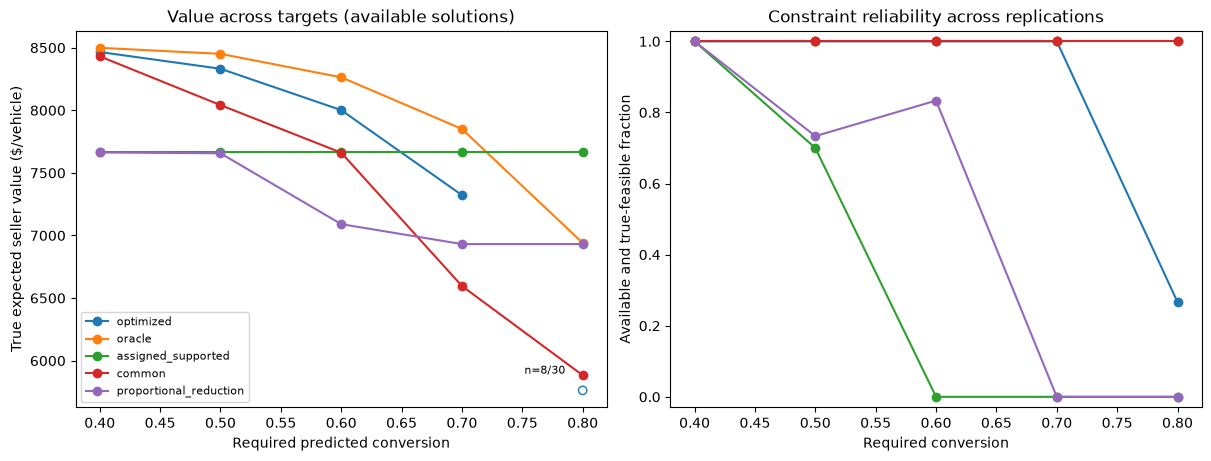

Completed main scenarios, sensitivities and bootstrap. Source hashes unchanged.


,scenario,target,policy,replications,availability,expected_conversion,expected_value,expected_gross,true_feasible_rate,realized_shortfall_rate,regret
50,binding_historical,0.4,assigned_supported,30,1.000000,0.512185,7663.404459,4578.094085,1.0,0.0,835.923831
51,binding_historical,0.4,common,30,1.000000,0.427926,8431.236015,4349.546285,1.0,0.233333,68.092276
52,binding_historical,0.4,optimized,30,1.000000,0.446738,8465.656559,4355.268291,1.0,0.133333,33.671732
53,binding_historical,0.4,oracle,30,1.000000,0.409666,8499.328291,4264.191396,1.0,0.366667,0.000000
54,binding_historical,0.4,proportional_reduction,30,1.000000,0.512185,7663.404459,4578.094085,1.0,0.0,835.923831
55,binding_historical,0.5,assigned_supported,30,1.000000,0.512185,7663.404459,4578.094085,0.7,0.366667,818.927751
56,binding_historical,0.5,common,30,1.000000,0.579567,8041.534219,5036.095570,1.0,0.0,409.506703
57,binding_historical,0.5,optimized,30,1.000000,0.552703,8331.901887,4716.328488,1.0,0.066667,119.139035
58,binding_historical,0.5,oracle,30,1.000000,0.500002,8451.040922,4599.406952,1.0,0.366667,0.000000
59,binding_historical,0.5,proportional_reduction,30,1.000000,0.513807,7656.592891,4582.593916,0.733333,0.3,828.932524


,max_q_error,max_gross_error
count,8.700000e+02,8.700000e+02
mean,6.737635e-05,1.051678e+00
std,7.209008e-05,1.089857e+00
min,2.220446e-16,9.094947e-13
25%,2.220446e-16,3.637979e-12
50%,6.974993e-05,1.090949e+00
75%,9.841736e-05,1.587507e+00
max,5.165776e-04,7.730271e+00


In [11]:
all_rows=[]
for folder in OUT.iterdir():
    if folder.is_dir() and folder.name!='bootstrap':
        files=sorted(folder.glob('rep_*.csv'))
        if files:
            t=pd.concat([pd.read_csv(p) for p in files],ignore_index=True);t['scenario']=folder.name;all_rows.append(t)
all_results=pd.concat(all_rows,ignore_index=True)
all_results.to_csv(OUT/'all_policy_results.csv',index=False)
summary=all_results.groupby(['scenario','target','policy']).agg(replications=('available','size'),availability=('available','mean'),
 expected_conversion=('expected_conversion','mean'),expected_value=('expected_value','mean'),expected_gross=('expected_gross','mean'),
 true_feasible_rate=('true_feasible','mean'),realized_shortfall_rate=('realized_below_target','mean'),regret=('regret','mean')).reset_index()
summary.to_csv(OUT/'policy_summary.csv',index=False)
paired=[]
for (scenario,target),group in all_results.groupby(['scenario','target']):
    opt=group[group.policy.eq('optimized')].set_index('replication')
    for baseline in ['assigned_supported','common','proportional_reduction','oracle']:
        other=group[group.policy.eq(baseline)].set_index('replication')
        for metric in ['expected_value','expected_conversion']:
            delta=(opt[metric]-other[metric]).dropna()
            if len(delta)<2:continue
            se=delta.std(ddof=1)/np.sqrt(len(delta));margin=student_t.ppf(.975,len(delta)-1)*se
            paired.append(dict(scenario=scenario,target=target,baseline=baseline,metric=metric,n=len(delta),mean=delta.mean(),
                               mcse=se,lower=delta.mean()-margin,upper=delta.mean()+margin))
paired=pd.DataFrame(paired);paired.to_csv(OUT/'paired_policy_differences.csv',index=False)
boot=pd.concat([pd.read_csv(p) for p in sorted((OUT/'bootstrap').glob('rep_*.csv'))],ignore_index=True)
boot.to_csv(OUT/'bootstrap_results.csv',index=False)
intervals=[]
for policy,g in boot.groupby('policy'):
    for metric in ['expected_value','expected_conversion','regret']:
        x=g[metric].dropna()
        intervals.append(dict(policy=policy,metric=metric,n=len(x),median=x.median(),lower=x.quantile(.025),upper=x.quantile(.975)))
pd.DataFrame(intervals).to_csv(OUT/'bootstrap_intervals.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
main=summary[summary.scenario.eq('binding_historical')]
for policy in ['optimized','oracle','assigned_supported','common','proportional_reduction']:
    g=main[main.policy.eq(policy)]
    axes[0].plot(g.target,g.expected_value.where(g.availability.eq(1)),'o-',label=policy)
    partial=g[g.availability.lt(1)]
    if len(partial):
        color=axes[0].lines[-1].get_color()
        axes[0].scatter(partial.target,partial.expected_value,facecolors='none',edgecolors=color)
        for _,row in partial.iterrows():
            axes[0].annotate(f"n={int(round(row.availability*row.replications))}/{int(row.replications)}",(row.target,row.expected_value),xytext=(-42,12),textcoords='offset points',fontsize=8)
    axes[1].plot(g.target,g.true_feasible_rate*g.availability,'o-',label=policy)
axes[0].set(xlabel='Required predicted conversion',ylabel='True expected seller value ($/vehicle)',title='Value across targets (available solutions)')
axes[1].set(xlabel='Required conversion',ylabel='Available and true-feasible fraction',ylim=(-.03,1.03),title='Constraint reliability across replications')
axes[0].legend(fontsize=8);fig.savefig(OUT/'conversion_value_frontier.png',dpi=180);plt.show()
# This figure is a fitted-policy comparison; only the oracle curve is the true constrained frontier.
numfiles=list(OUT.glob('*/oracle_*.csv'))
numeric=pd.concat([pd.read_csv(p).assign(source=str(p)) for p in numfiles],ignore_index=True)
numeric.to_csv(OUT/'oracle_numerical_checks.csv',index=False)
config=dict(n=N,portfolio=PORTFOLIO,replications=REPLICATIONS,bootstraps=BOOTSTRAPS,targets=TARGETS,
            sensitivities=SENSITIVITIES,primary_calibration='chronological validation only',
            oracle_information='fixed observable recorded reference floor; never candidate-conditioned latent posterior',
            oracle_nodes=ORACLE_NODES,oracle_check_nodes=ORACLE_CHECK_NODES,
            seconds=time.perf_counter()-started,packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn']})
(OUT/'study_metadata.json').write_text(json.dumps(config,indent=2)+'\n')
assert len(boot.bootstrap.unique())==BOOTSTRAPS
for institution,assignment in MAIN:
    assert all_results.loc[all_results.scenario.eq(institution+'_'+assignment),'replication'].nunique()==REPLICATIONS
for name,digest in metadata['source_sha256'].items():
    with (Path('Larsen_used_car_bargaining_data_and_code')/name).open('rb') as f:assert hashlib.file_digest(f,'sha256').hexdigest()==digest
print('Completed main scenarios, sensitivities and bootstrap. Source hashes unchanged.')
display(summary[summary.scenario.eq('binding_historical')])
display(numeric[['max_q_error','max_gross_error']].describe())
